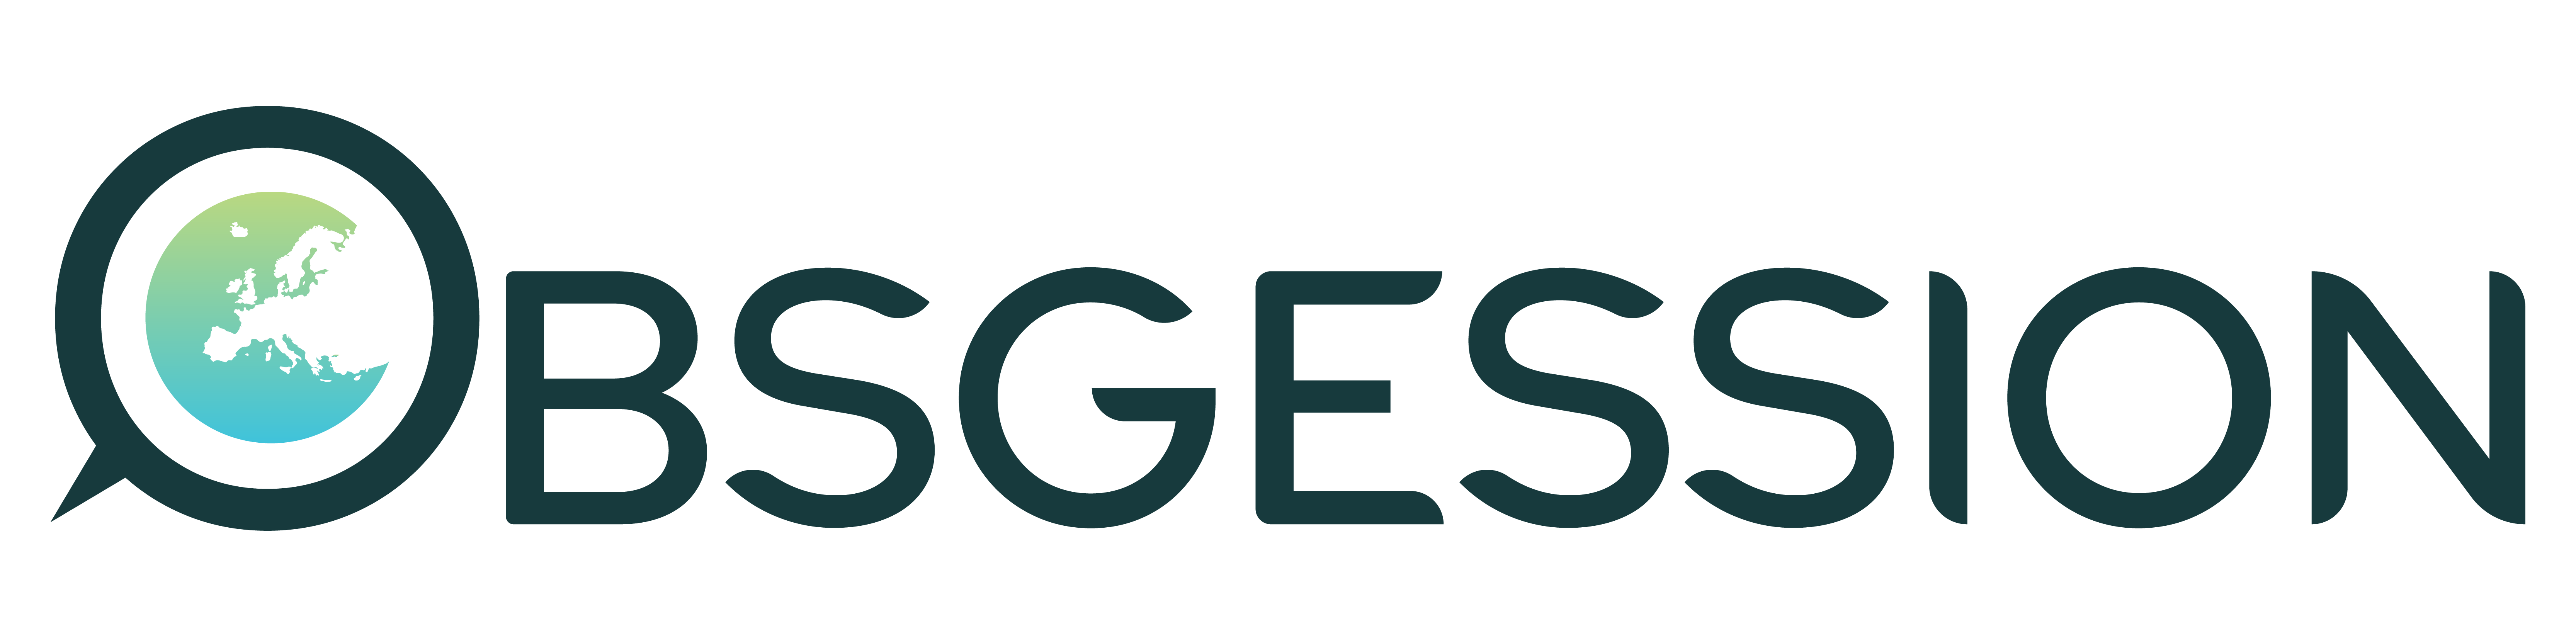

# How to bring own ML models into openEO - the usage of ONNX
### data processing with openEO - introduction to use the VITO eo_processing package for Principal component analysis

Authors:

* Jeroen Wannijn
* Dr. Marcel Buchhorn (VITO)


To run this Jupyter notebook you need the following:
- an CDSE account for data processing in [openEO](https://dataspace.copernicus.eu/). Via green button in the right top corner; following the [documentation to register](https://documentation.dataspace.copernicus.eu/Registration.html).
- an Anaconda Python environment with all needed packages installed
    - follow this manual to set up the Python environment: [python_dev_environment](https://github.com/ESA-WEED-project/.github/tree/main/python_dev_environment)
    - install the eo_processing package in your conda environment:
        - run `conda activate <your_env_name>`
        - run `pip install git+https://github.com/ESA-WEED-project/eo_processing.git@main#egg=eo_processing`

## ADVANCED example - PCA on Sentinel-2 pipeline
Copyrights, license and restrictions
All code snippets, visualizations or/and workflow ideas are property of VITO. Showed public and private repositories are owned by VITO.
(Re)sharing is only allowed with proper citation of the owners. Publications (peer-review, reports, ...) based partly and/or fully on VITO's hierarchical habitat mapping framework or on one of the provided GitHub repositories must be prior aligned with Dr. Marcel Buchhorn. Code usage is allowed with proper citation, see author list in repository.
base repository: https://github.com/ESA-WEED-project/eo_processing

### Steps whithin the notebook

This notebook will show on an easy example how to create own ML models and how to run them in openEO:
- Train a PCA model on on extracted Sentinel-2 features to reduce all features in the Sentinel-2 data cube to 3 principal components.
- convert model into ONNX format and stage on openEO reachable storage
- prepare UDFs to run the model on the data cube
  - UDF that selects the significant raw bands from the dimensionality reduction model for custom area of interest
  - UDF job that executes the dimensionality reduction model on Sentinel-2 master cube for custom area
- run all

Note: The main points are to show how to stage a ONNX model that openEO can access it and the UDF which is needed to apply the ONNX model in openEO on a dataset.

Import dependencies

In [32]:
# Standard library imports
import zipfile
import os

# Third-party imports
import matplotlib.pyplot as plt
import numpy as np
import openeo
from openeo.extra.artifacts import build_artifact_helper
import xarray as xr
from sklearn.decomposition import PCA
import pandas as pd

# Local imports
from eo_processing.utils.onnx_model_utilities import convert_model_to_onnx_with_metadata
from eo_processing.utils.helper import init_connection
from eo_processing.config import get_job_options, get_collection_options, get_standard_processing_options
from eo_processing.openeo.processing import generate_master_feature_cube

# Check OpenEO and eo_processing version
openeo.client_version()
from eo_processing._version import __version__
print(f"OpenEO version: {openeo.client_version()}")
print(f"eo_processing version: {__version__}")


OpenEO version: 0.45.0
eo_processing version: 0.3.3


### declaration area

In [5]:
base_path = os.path.normpath(r'C:\Users\BUCHHORM\Downloads\PCA_base')
os.makedirs(base_path, exist_ok=True)

### Authentication to openEO

In [7]:
backend = 'cdse'
# establish the connection to the selected backend
connection = init_connection(backend)

Authenticated using refresh token.


### prepare PCA model
we load data from training point features prepared in an other example

In [14]:
df = pd.read_parquet(os.path.normpath('test_data/features_TP_2024.parquet'))
# remove some openEO generated columns
feature_names = [x for x in df.columns.tolist() if x not in ["date", "feature_index", "geometry", "MGRSid10"]]

In [15]:
# prepare training data in shape (n_samples, n_features)
np_train = df[feature_names].to_numpy()

# Train model
MODEL_PARAMS = {
    "random_state": 42,
    "n_components": 3
}
model = PCA(**MODEL_PARAMS)
model.fit(np_train)

PCA(n_components=3, random_state=42)

### convert model to ONNX with needed metadata

In [16]:
# metadata keys to extract from the trained model
metadata_keys = [
    "n_components_", "components_", "explained_variance_",
    "explained_variance_ratio_", "mean_", "n_features_", "n_samples_"
]

# Get `model` metadata from your trained PCA model
add_metadata_dict = {}
for key in metadata_keys:
    if hasattr(model, key):
        value = getattr(model, key)
        # Convert numpy arrays or other complex types to lists
        if hasattr(value, "tolist"):
            value = value.tolist()
        add_metadata_dict[key] = value

# Convert to ONNX via our eo_processing package functionality
convert_model_to_onnx_with_metadata(
    model=model,
    input_features=feature_names,
    output_features = [f'COMP{i}' for i in range(1, MODEL_PARAMS['n_components'] + 1)],
    output_onnx_path= os.path.join(base_path, "dim_reduction_pca.onnx"),
    add_metadata=add_metadata_dict
)

Type model: PCA(n_components=3, random_state=42)
scikit-learn base model saved to ONNX: dim_reduction_pca.onnx
Reload ONNX model from dim_reduction_pca.onnx for metadata infusion
Metadata added: input_features = ['B02_p2', 'B02_p25', 'B02_median', 'B02_p75', 'B02_p98', 'B02_mean', 'B02_sd', 'B02_sum', 'B02_iqr', 'B03_p2', 'B03_p25', 'B03_median', 'B03_p75', 'B03_p98', 'B03_mean', 'B03_sd', 'B03_sum', 'B03_iqr', 'B04_p2', 'B04_p25', 'B04_median', 'B04_p75', 'B04_p98', 'B04_mean', 'B04_sd', 'B04_sum', 'B04_iqr', 'B05_p2', 'B05_p25', 'B05_median', 'B05_p75', 'B05_p98', 'B05_mean', 'B05_sd', 'B05_sum', 'B05_iqr', 'B06_p2', 'B06_p25', 'B06_median', 'B06_p75', 'B06_p98', 'B06_mean', 'B06_sd', 'B06_sum', 'B06_iqr', 'B07_p2', 'B07_p25', 'B07_median', 'B07_p75', 'B07_p98', 'B07_mean', 'B07_sd', 'B07_sum', 'B07_iqr', 'B08_p2', 'B08_p25', 'B08_median', 'B08_p75', 'B08_p98', 'B08_mean', 'B08_sd', 'B08_sum', 'B08_iqr', 'B8A_p2', 'B8A_p25', 'B8A_median', 'B8A_p75', 'B8A_p98', 'B8A_mean', 'B8A_sd', '

----
#### here some overview plotting just as info

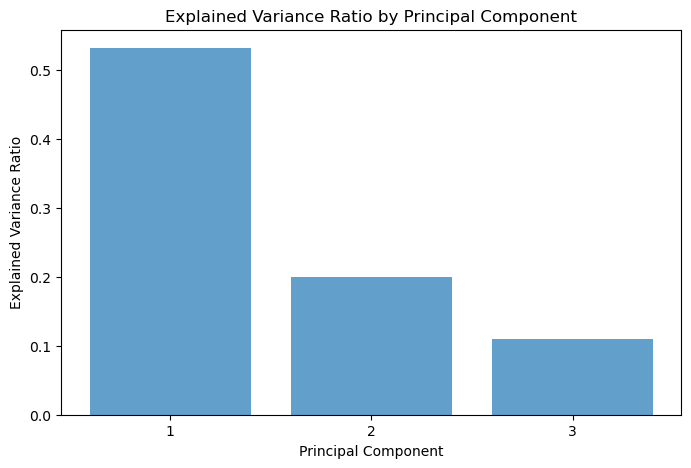

In [25]:
explained_variance_ratio = add_metadata_dict["explained_variance_ratio_"]

plt.figure(figsize=(8,5))
plt.bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, alpha=0.7)
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Component')
plt.title('Explained Variance Ratio by Principal Component')
plt.xticks(range(1, len(explained_variance_ratio) + 1))
plt.show()

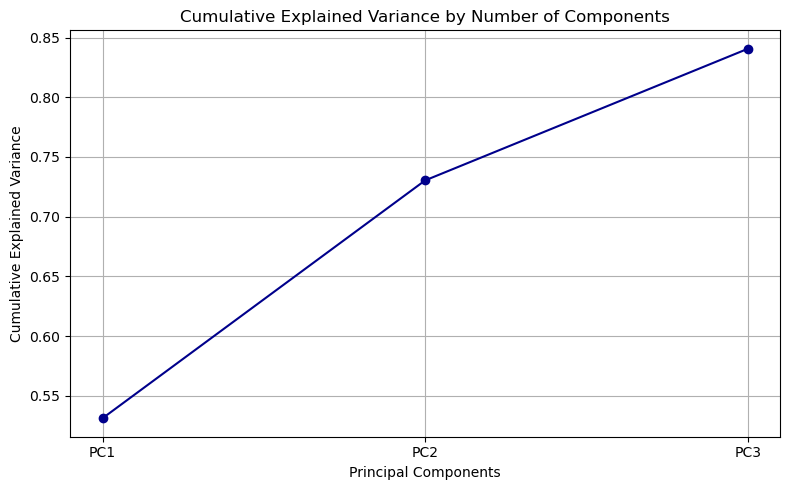

In [26]:
cumulative_variance = np.cumsum(explained_variance_ratio)

# Create x-tick labels like "PC1", "PC2", ...
pc_labels = [f'PC{i}' for i in range(1, len(cumulative_variance) + 1)]

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='-', color='darkblue')
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by Number of Components')
plt.xticks(ticks=range(1, len(cumulative_variance) + 1), labels=pc_labels)
plt.grid(True)
plt.tight_layout()
plt.show()

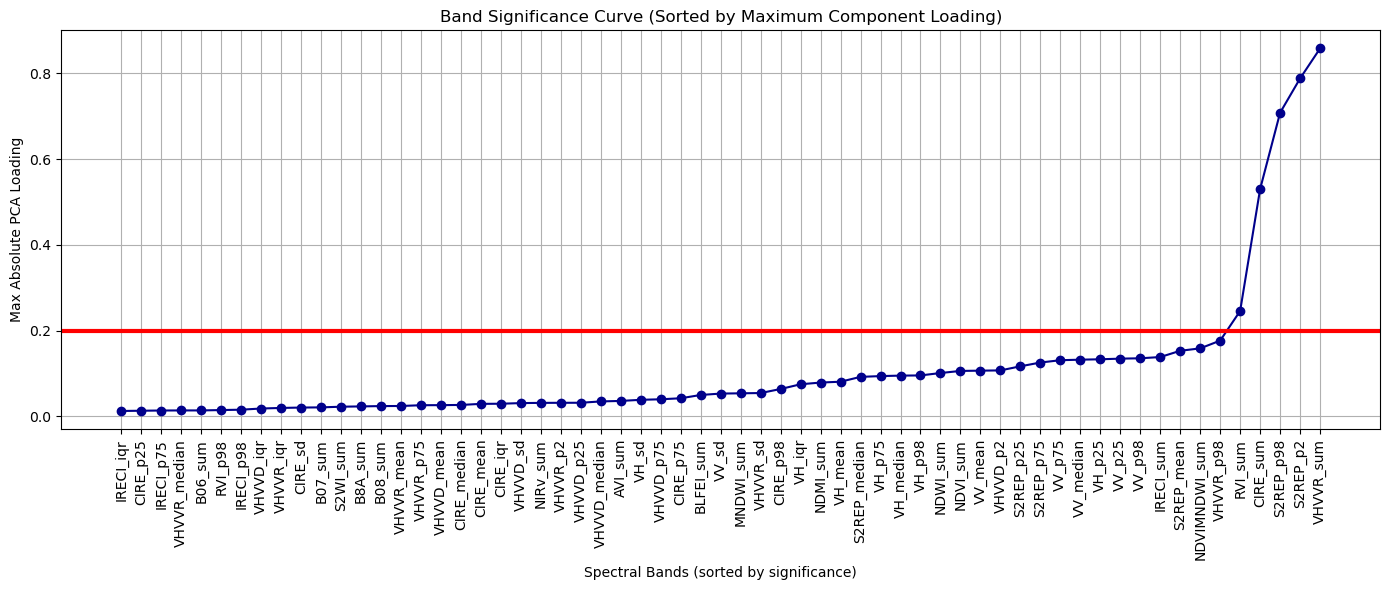

In [27]:
components = add_metadata_dict["components_"]  # shape: (n_components, n_bands)
original_band_names= feature_names

threshold = 0.01 # define significance threshold

# Find bands with at least one loading above threshold (in absolute value)
significant_bands_mask = np.any(np.abs(components) >= threshold, axis=0)

# Calculate aggregate importance per band (e.g., max absolute loading across PCs)
band_importance = np.max(np.abs(components), axis=0)  # or use np.sum(...) or np.mean(...)

# Only keep significant bands
band_importance_significant = band_importance[significant_bands_mask]
significant_band_names = np.array(original_band_names)[significant_bands_mask]

# Sort by importance
sorted_indices = np.argsort(band_importance_significant)
sorted_importance = band_importance_significant[sorted_indices]
sorted_band_names = significant_band_names[sorted_indices]

# Plot as a curve
plt.figure(figsize=(14, 6))
plt.plot(sorted_importance, marker='o', linestyle='-', color='darkblue')
plt.axhline(y=0.20, color='red', linewidth=3)  # <-- Add this line
plt.xticks(ticks=np.arange(len(sorted_band_names)), labels=sorted_band_names, rotation=90)
plt.title('Band Significance Curve (Sorted by Maximum Component Loading)')
plt.ylabel('Max Absolute PCA Loading')
plt.xlabel('Spectral Bands (sorted by significance)')
plt.grid(True)
plt.tight_layout()
plt.show()

----

### Stage model in a storage reachable for openEO
we use the openEO internal artifact system. But we have to zip the model to be automatically transferred with the job_options)

In [19]:
# Paths
onnx_file = os.path.join(base_path, "dim_reduction_pca.onnx")
zip_file = os.path.join(base_path, "onnx_reduction_models.zip")

# Step 1: Zip the ONNX model
with zipfile.ZipFile(zip_file, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(onnx_file, arcname=os.path.basename(onnx_file))

print(f"Created zip file: {zip_file}")

Created zip file: C:\Users\BUCHHORM\Downloads\PCA_base\onnx_reduction_models.zip


In [22]:
# init artefact & upload to common S3 bucket
ah = build_artifact_helper(connection)
s3_url = ah.upload_file(zip_file)

# create presigned url which can be used (max. 7 days)
artefact_url = ah.get_presigned_url(s3_url)

print(f"Data stored at: '{artefact_url}'")

Data stored at: 'https://s3.waw3-1.openeo.v1.dataspace.copernicus.eu/openeo-artifacts-waw3-1/3921162783d8ab8324e389894b356987f8fe1d45/2025/11/04/onnx_reduction_models.zip?X-Proxy-Head-As-Get=True&X-Amz-Algorithm=AWS4-HMAC-SHA256&X-Amz-Credential=4c2adcfc5fc743c8ad0785d1d76619bf%2F20251104%2Fwaw3-1%2Fs3%2Faws4_request&X-Amz-Date=20251104T204516Z&X-Amz-Expires=604800&X-Amz-SignedHeaders=host&X-Amz-Security-Token=eyJhbGciOiJSUzI1NiIsInR5cCI6IkpXVCJ9.eyJyb2xlX2FybiI6ImFybjpvcGVuZW86aWFtOjo6cm9sZS9vcGVuZW8tYXJ0aWZhY3RzLXdhdzMtMSIsImluaXRpYWxfaXNzdWVyIjoiaHR0cHM6Ly9pZGVudGl0eS5kYXRhc3BhY2UuY29wZXJuaWN1cy5ldS9hdXRoL3JlYWxtcy9DRFNFIiwiaHR0cHM6Ly9hd3MuYW1hem9uLmNvbS90YWdzIjp7InByaW5jaXBhbF90YWdzIjpudWxsfSwiaXNzIjoic3RzLndhdzMtMS5vcGVuZW8udjEuZGF0YXNwYWNlLmNvcGVybmljdXMuZXUiLCJzdWIiOiIxMzEyOTQ5Ny0wNWY2LTQ1MjAtOGI2My01Yjc2MjQ5NTlkZDgiLCJleHAiOjE3NjIzMzIzMTUsIm5iZiI6MTc2MjI4OTExNSwiaWF0IjoxNzYyMjg5MTE1LCJqdGkiOiI2MDIzNzY3MS04MzMzLTRlNzctOWE2Zi0xZDJlOTMxNmZiZmUiLCJhY2Nlc3Nfa2V5X2lkIjoiNGMyYWRjZmM1Z

### add the link to the ONNX model to the openEO job_options

Set Job options for OpenEO functionalities, be sure to include ONNX dependencies not included in OpenEO by standard
--> we can use the eo_processing job options for inference for that

In [36]:
job_options = get_job_options(provider=backend, task='inference')

append url from uploaded model to use in UDF's

In [37]:
job_options['udf-dependency-archives'].append(f"{artefact_url}#onnx_models")
# we need a little bit more memory since nothing is optimized in this test
job_options.update({'driver-memory': '4000m', 'executor-memory': '2500m', 'executor-memoryOverhead': '2000m'})
job_options

{'driver-memory': '4000m',
 'driver-memoryOverhead': '1000m',
 'driver-cores': 1,
 'executor-memory': '2500m',
 'executor-memoryOverhead': '2000m',
 'executor-cores': 1,
 'max-executors': 20,
 'soft-errors': 'true',
 'python-memory': '4000m',
 'logging-threshold': 'info',
 'udf-dependency-archives': ['https://s3.waw3-1.cloudferro.com/swift/v1/project_dependencies/onnx_deps_python311.zip#onnx_deps',
  'https://s3.waw3-1.openeo.v1.dataspace.copernicus.eu/openeo-artifacts-waw3-1/3921162783d8ab8324e389894b356987f8fe1d45/2025/11/04/onnx_reduction_models.zip?X-Proxy-Head-As-Get=True&X-Amz-Algorithm=AWS4-HMAC-SHA256&X-Amz-Credential=4c2adcfc5fc743c8ad0785d1d76619bf%2F20251104%2Fwaw3-1%2Fs3%2Faws4_request&X-Amz-Date=20251104T204516Z&X-Amz-Expires=604800&X-Amz-SignedHeaders=host&X-Amz-Security-Token=eyJhbGciOiJSUzI1NiIsInR5cCI6IkpXVCJ9.eyJyb2xlX2FybiI6ImFybjpvcGVuZW86aWFtOjo6cm9sZS9vcGVuZW8tYXJ0aWZhY3RzLXdhdzMtMSIsImluaXRpYWxfaXNzdWVyIjoiaHR0cHM6Ly9pZGVudGl0eS5kYXRhc3BhY2UuY29wZXJuaWN1cy5ldS9hd

## now we prepare UDF (User Defined Functions) to apply the ONNX models on openEO datacubes
normally we just load the UDF code from file, but better understanding we will develop the UDF Python code in the notebook. We just apply the PCA dimension reduction on a openEO datacube.

In [38]:
# Build a UDF object from an inline string with Python source code.
pca_udf_obj = openeo.UDF(
'''
import sys
import functools
import glob
import xarray as xr
from sklearn.preprocessing import MinMaxScaler
from openeo.udf import inspect
from openeo.metadata import CubeMetadata
from typing import List, Tuple, Dict
import numpy as np

sys.path.append("onnx_deps")
import onnxruntime as ort


def apply_metadata(metadata: CubeMetadata, context: dict) -> CubeMetadata:
    """Rename and filter the bands by using apply metadata to only keep dimensionality reduction model components

    :param metadata: Metadata of the input data
    :param context: Optional dictionary containing configuration values.
                    Expected key:
                        - "model_id" (str): The filename of the model, whitout the 'onnx' extension
    :return: Filtered & renamed components of labels
    """
    # Get model type
    model_id = (context or {}).get("model_id", "")

    # Get amount of components from the model in the context
    _, metadata_dict = load_pca_model(model_id=model_id)

    # rename and reduce band labels to component labels
    metadata = metadata.rename_labels(dimension="bands", target=metadata_dict["output_features"])
    metadata = metadata.filter_bands(metadata_dict["output_features"])

    # rename band labels
    return metadata

def find_model_file(model_id: str) -> str:
    """
    Locates a serialized dimensionality reduction model file within common temporary directories.

    This function searches recursively through the working directory
    to locate a model file named according to the pattern `<model_id>.onnx`.
    It assumes the file has been extracted from the job’s dependency archive into a subdirectory of
    structure like `/opt/*/work-dir/models/`, corresponding to the driver's working directory.

    :param model_id: The filename of the model, whitout the 'onnx' extension
    :return: The full file path to the located model file.
    :raises FileNotFoundError: If the model file cannot be found in any of the predefined directories.
    """
    # Look in likely temp dirs
    model_filename = f"{model_id.lower()}.onnx"

    # Model file should always be unzipped from working-directory of the Driver
    for path in glob.glob(f"/opt/**/work-dir/onnx_models/**/{model_filename}", recursive=True):
        inspect(message=f"Found model file: {path}")
        return path

    raise FileNotFoundError(f"Model file {model_filename} not found in the working directory")


def run_inference(input_np: np.ndarray, ort_session: ort.InferenceSession) -> np.ndarray:
    """
    Executes inference using an ONNX Runtime session and input numpy array. This function
    returns the dimensionality-reduced output.

    :param input_np: Numpy array containing the input tensor data for inference.
    :param ort_session: ONNX Runtime inference session object used to execute the dimensionality reduction model.
    :return: Numpy array containing the dimensionality-reduced features.
    """
    ort_inputs = {ort_session.get_inputs()[0].name: input_np}
    ort_outputs = ort_session.run(None, ort_inputs)
    transformed = ort_outputs[0]
    return transformed


@functools.lru_cache(maxsize=1)
def load_pca_model(model_id: str) -> Tuple[ort.InferenceSession, Dict[str, List[str]]]:
    """
    Loads a dimensionality reduction from a given URL, caches the model locally, and initializes an dimensionality reduction session.

    The function ensures the dimensionality reduction model is locally stored in the specified driver directory
    to optimize repeated access. It also validates if the file is a dimensionality reduction model.

    :param model_id: The filename of the model, whitout the 'onnx' extension
    :return: A dimensionality reduction model
    :raises ValueError: If model_id is invalid or if the model file is not found or invalid.
    """
    # Process the model file to ensure it's a valid dimensionality reduction technique model
    model_path = find_model_file(model_id.lower())
    inspect(message=f"Downloading model file from {model_path}...")

    # Initialize the ONNX Runtime session
    inspect(message=f"Initializing ONNX Runtime session for model at {model_path}...")
    ort_session = ort.InferenceSession(model_path, providers=["CPUExecutionProvider"])

    # Extract metadata
    model_meta = ort_session.get_modelmeta()

    input_features = model_meta.custom_metadata_map.get("input_features", "")
    if input_features:
        if input_features.startswith('"') and input_features.endswith('"'):
            input_features = input_features[1:-1]
    input_features = [band.strip() for band in input_features.split(",")]

    output_features = model_meta.custom_metadata_map.get("output_features", "")
    if output_features:
        if output_features.startswith('"') and output_features.endswith('"'):
            output_features = output_features[1:-1]
    output_features = [band.strip() for band in output_features.split(",")]
    n_components = len(output_features)
    inspect(message=f"Dimensionality reduction components: {n_components}")

    metadata = {
        "input_features": input_features,
        "output_features": output_features,
        "n_components": n_components
    }

    inspect(message=f"Successfully extracted metadata from model at {model_path}...")
    return ort_session, metadata


def preprocess_input(input_xr: xr.DataArray) -> Tuple[np.ndarray, Tuple[int, int, int]]:
    """
    Preprocesses input data for model inference using an ONNX runtime session. This
    function takes an xarray DataArray, rearranges its dimensions, and reshapes its
    values to match the input requirements of the ONNX model specified by the given
    ONNX InferenceSession.

    :param input_xr: Input data in the format of an xarray DataArray. The expected
        dimensions are "y", "x", and "bands", and the order of the dimensions will
        be transposed to match this requirement.
    :param ort_session: ONNX runtime inference session that specifies the model for
        inference. Used to determine the required input shape of the model.
    :return: A tuple containing:
        - A numpy array formatted to fit the input shape of the ONNX model.
        - The original shape of the input data as a tuple with the transposed "y",
          "x", and "bands" dimensions.
    """
    # Ensure input is in ('bands', 'y', 'x') order
    input_xr = input_xr.transpose("y", "x", "bands")
    input_shape = input_xr.shape
    inspect(message=f"Input dims: {input_xr.dims}, shape: {input_xr.shape}")

    # Make numpy array
    input_np = input_xr.values.reshape(-1, input_xr.shape[-1])

    return input_np, input_shape


def create_output_xarray(transformed: np.ndarray, original_shape: Tuple[int, int, int], input_xr: xr.DataArray) -> xr.DataArray:
    """
    Generate an xarray.DataArray based on dimensionality reduction components and the
    coordinate information from the input xarray.DataArray. This function structures
    the component data into a 3D DataArray with spatial alignment inherited from the input.

    :param n_components: The number of components (e.g., principal components) generated
        by a dimensionality reduction algorithm.
    :param components: A 3D array (xarray.DataArray or NumPy array) containing component values
        with shape [n_components, y, x].
    :param input_xr: The input xarray.DataArray used to extract the 'x' and 'y' coordinates,
        ensuring spatial alignment in the output.
    :return: An xarray.DataArray with dimensions ['bands', 'y', 'x'], where 'bands' are
        labeled as "COMP1", "COMP2", etc., and spatial coordinates are taken from input_xr.
    """
    # Construct DataArray output
    y, x, _ = original_shape
    n_components = transformed.shape[1]

    # Normalize component weights
    scaler = MinMaxScaler()
    transformed_normalized = scaler.fit_transform(transformed)
    inspect(message=f"Normalizing ouput components...")

    # Reshape back to (n_components/back, y, x)
    reshaped = transformed_normalized.T.reshape((n_components, y, x))

    # Construct output array
    coords = {
        "bands": [f"COMP{i+1}" for i in range(n_components)],
        "y": input_xr.coords["y"],
        "x": input_xr.coords["x"],
    }

    result = xr.DataArray(reshaped, dims=("bands", "y", "x"), coords=coords)
    inspect(message=f"Output dims: {result.dims}, shape: {result.shape}")

    # Attach input cube attrs
    result.attrs = input_xr.attrs
    result = result.rename('__xarray_dataarray_components__')

    return result


def apply_datacube(cube: xr.DataArray, context: dict = None) -> xr.DataArray:
    """
    Applies a dimensionality reduction model on a given data cube for dimensionality reduction.
    The function ensures that the input cube is processed to fill any missing values and
    is in the correct data type to be compatible with the models.

    Note: The function name and arguments are defined by the UDF API.
    More information can be found here:
    https://open-eo.github.io/openeo-python-client/udf.html#udf-function-names-and-signatures

    :param cube: The data cube on which dimensionality reduction will be applied. It must be an `xr.DataArray`.
    :param context: Optional dictionary containing configuration values.
                    Expected key:
                        - "model_id" (str): The filename of the model, whitout the 'onnx' extension
    :return: An `xr.DataArray` representing the processed output cube after successfully applying the model
    """
    # fill nan in cube and make sure cube is in right dtype for dimensionality reduction
    cube = cube.fillna(0)
    cube = cube.astype("float32")

    # Get model type
    model_id = (context or {}).get("model_id", "")
    inspect(message=f"Running model: {model_id}")

    # Load the ONNX model and extract metadata
    ort_session, _ = load_pca_model(model_id=model_id)

    # preprocess input array to numpy array in correct shape
    input_np, input_shape = preprocess_input(cube)

    # Apply Dimensionality Reduction model by running inference
    inspect(message=f"Running inference ...")
    component_array = run_inference(input_np, ort_session)

    # Build coords and return xr.DataArray
    result = create_output_xarray(transformed=component_array,
                                  original_shape=input_shape,
                                  input_xr=cube)

    # make sure output Xarray has the correct dtype
    result = result.astype("float32")
    return result
''',
    context={"model_id": "dim_reduction_pca"},
    runtime="Python",
    version="3.11"
)

## create the data cube in openEO to apply the ONNX model on

In [39]:
processing_options = get_standard_processing_options(provider=backend,
                                                     task='feature_generation') #standard create over 230 features
collection_options = get_collection_options(provider=backend)
BBOX = {"east": 4878500, "south": 2897000, "west": 4877000, "north": 2898500, 'crs': 'EPSG:3035'} # 1.5x1.5km bbox in Germany
DATE_START = "2024-01-01"
DATE_END = "2025-01-01"

In [40]:
# define the openEO pipeline to use from the `eo_processing` package pool
data_cube = generate_master_feature_cube(connection,
                                         BBOX,
                                         DATE_START,
                                         DATE_END,
                                         **collection_options,
                                         **processing_options)

### UDF execution - apply PCA dimensionality reduction

Apply the Dimensionality Reduction UDF with PCA within a neighbourhood of 512x512 pixels to reduce the features to 3 new principal components

In [41]:
components = data_cube.apply_neighborhood(
    process=pca_udf_obj,
    size=[
        {"dimension": "x", "value": 384, "unit": "px"},
        {"dimension": "y", "value": 384, "unit": "px"},
    ],
    overlap=[
        {"dimension": "x", "value": 64, "unit": "px"},
        {"dimension": "y", "value": 64, "unit": "px"},
    ],
)
pca_job = components.create_job(
    title="apply_pca_job", out_format="NetCDF", job_options=job_options
)
pca_job.start_and_wait()
pca_job.download_result(os.path.join(base_path, "results_pca.nc"))

0:00:00 Job 'j-2511042131054af087fc927477b7185a': send 'start'
0:00:19 Job 'j-2511042131054af087fc927477b7185a': created (progress 0%)
0:00:24 Job 'j-2511042131054af087fc927477b7185a': created (progress 0%)
0:00:30 Job 'j-2511042131054af087fc927477b7185a': created (progress 0%)
0:00:38 Job 'j-2511042131054af087fc927477b7185a': created (progress 0%)
0:00:48 Job 'j-2511042131054af087fc927477b7185a': created (progress 0%)
0:01:05 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:01:22 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:01:41 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:02:05 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:02:35 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:03:15 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:04:02 Job 'j-2511042131054af087fc927477b7185a': running (progress N/A)
0:05:00 Job 'j-2511042131054af087fc927477b7185a': running (progres

WindowsPath('C:/Users/BUCHHORM/Downloads/PCA_base/results_pca.nc')

## Visualise Output

In [42]:
pca_job_data = xr.open_dataset(os.path.join(base_path, "results_pca.nc"))

In [43]:
def concat_features_to_bands_dim(ds: xr.DataArray):
    # List band variables
    band_vars = [var for var in ds.data_vars if ds[var].dtype.kind in 'fc' and set(ds[var].dims) == {'y', 'x'}]

    cube = xr.concat([ds[var] for var in band_vars], dim="bands")
    cube = cube.assign_coords(bands=band_vars)  # name the bands
    return cube.rename('__xarray_dataarray_variable__')

def plot_components(data_array: xr.DataArray, model_name: str):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    print(type(data_array))

    for i, ax in enumerate(axes):
        comp_data = np.abs(data_array.isel(bands=i))  # take absolute value here

        # Use percentiles to plot as vmin & vmax to highlight differences
        vmin = comp_data.quantile(0.05).item()
        vmax = comp_data.quantile(0.95).item()

        im = ax.imshow(comp_data, vmin=vmin, vmax=vmax)
        ax.set_title(f'COMP{i+1}')
        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Add a general title
    fig.suptitle(f"{model_name} Components", fontsize=16)

    plt.tight_layout()
    plt.show()

<class 'xarray.core.dataarray.DataArray'>


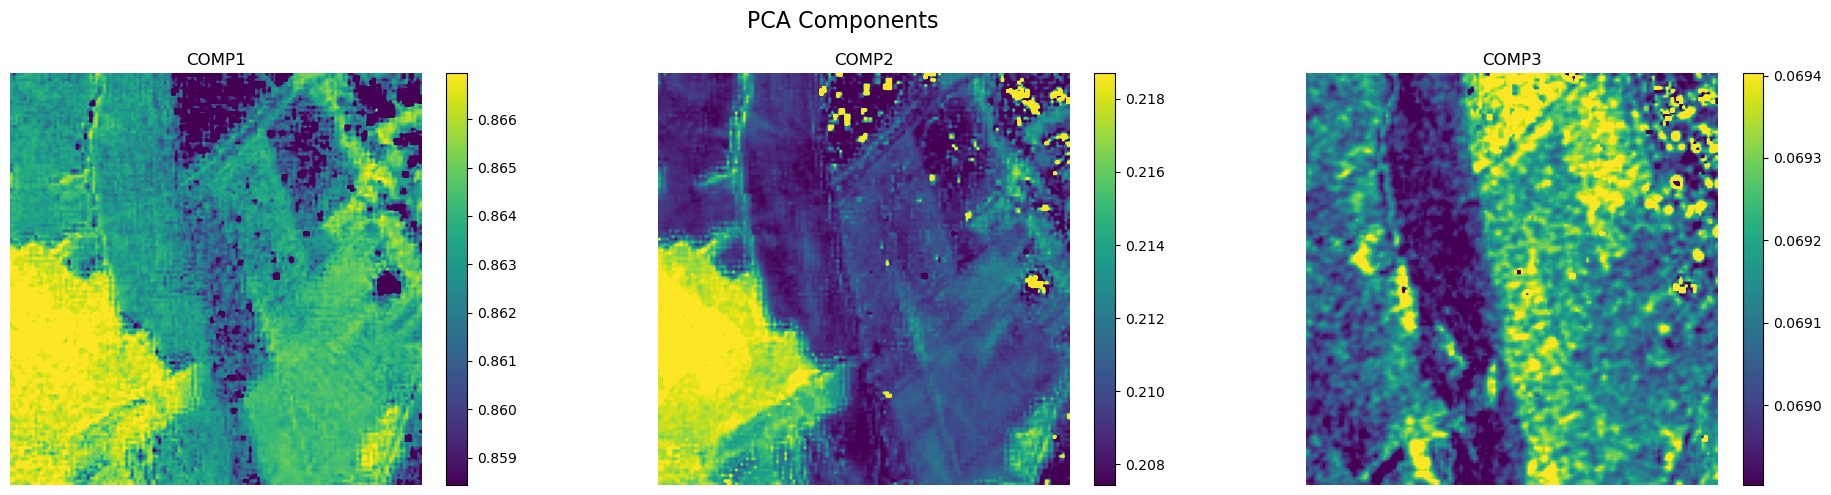

In [44]:
pca_job_data_array= concat_features_to_bands_dim(pca_job_data)
plot_components(pca_job_data_array, "PCA")

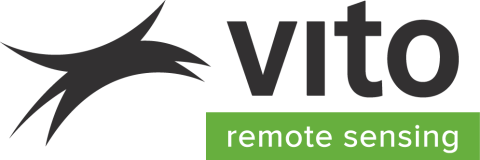